# Honcho

**The idea in one screen.** [Honcho](https://github.com/plastic-labs/honcho),
from Plastic Labs, treats memory as reasoning. Every stored item is a
*conclusion* at a stated level of certainty, and it records the conclusions it
was drawn from.

| Level | Means | Example |
|---|---|---|
| `EXPLICIT` | they said it | *Anton is vegetarian* |
| `DEDUCTIVE` | it follows necessarily | *Anton does not eat chicken* |
| `INDUCTIVE` | a pattern, likely true | *Anton plans meals carefully around constraints* |
| `ABDUCTIVE` | a guess about why | *Anton may have had a bad allergic reaction in the past* |

Extraction of what was said happens when messages arrive. The higher levels
are worked out later, by a background process Honcho calls the *dreamer*.
Because each conclusion keeps its premises, when one of them stops being true
the system can find everything that was resting on it.

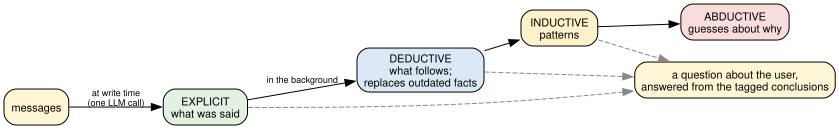

In [1]:
import graphviz

picture = graphviz.Digraph(
    graph_attr={"rankdir": "LR", "bgcolor": "white", "nodesep": "0.3"},
    node_attr={"shape": "box", "style": "rounded,filled", "fontname": "Helvetica", "fontsize": "11",
               "fillcolor": "#eef3f8"},
    edge_attr={"fontname": "Helvetica", "fontsize": "9"},
)
picture.node("chat", "messages", fillcolor="#fff6d6")
picture.node("explicit", "EXPLICIT\nwhat was said", fillcolor="#e3f1e3")
picture.node("deductive", "DEDUCTIVE\nwhat follows;\nreplaces outdated facts", fillcolor="#dbe9f6")
picture.node("inductive", "INDUCTIVE\npatterns", fillcolor="#fff1c9")
picture.node("abductive", "ABDUCTIVE\nguesses about why", fillcolor="#f9dcdc")
picture.node("answer", "a question about the user,\nanswered from the tagged conclusions", fillcolor="#fff6d6")
picture.edge("chat", "explicit", label="at write time\n(one LLM call)")
picture.edge("explicit", "deductive", label="in the background")
picture.edge("deductive", "inductive")
picture.edge("inductive", "abductive")
for level in ("explicit", "deductive", "inductive"):
    picture.edge(level, "answer", style="dashed", color="#888888")
picture

Each arrow between levels also runs backwards as a record: a conclusion keeps
the ids of the conclusions it was drawn from, and a premise must always sit at
a lower level than what is concluded from it.

Five questions:

1. **Extraction.** What does an extractor that knows its certainty level keep?
2. **Deduction.** What does the second level add, and what does it remove?
3. **The level rule.** Can *"a premise must rank below its conclusion"* be
   enforced by code?
4. **Retraction.** When the user changes their mind, what happens to the old
   fact, and to what was concluded from it?
5. **Induction and abduction.** What do the pattern and hypothesis levels
   produce, and why is the last one risky?

## What is run here

A **re-implementation**, not Honcho itself.

- Honcho's server is open source (AGPL-3.0), so its prompts and control flow
  can be read. Section 0 reads them to establish what the pipeline does.
- The prompts used below are **ours**, written from Honcho's published
  definitions of the four levels. The store is a small Python class.
- Honcho's own reasoning models, which it calls Neuromancer, are not
  published. A general small model does the reasoning here, so the outputs
  are not Honcho's outputs. What carries over is the mechanism.

## Setup

The model is set in [`config.py`](config.py), which also reads `GEMINI_API_KEY`
from the `.env` at the top of the repository. There is no vector store: the
representation is a set of conclusions with links between them, so a
dictionary is enough.

In [2]:
import json
import textwrap
import urllib.request
from dataclasses import dataclass, field
from datetime import date

import pandas as pd

from config import CHAT_MODEL, generate

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
print(f"chat model: {CHAT_MODEL}")

chat model: gemini-3.1-flash-lite


Every model call in this notebook goes through one function, which keeps a log
of prompts, replies and token counts.

In [3]:
CALLS = []


def ask(prompt, label, as_json=True):
    """One model call, logged."""
    reply = generate(prompt, as_json=as_json)
    CALLS.append({
        "label": label,
        "tokens in": reply.usage_metadata.prompt_token_count,
        "tokens out": reply.usage_metadata.candidates_token_count or 0,
        "prompt": prompt,
        "reply": reply.text,
    })
    return reply.text.strip()


def ask_json(prompt, label):
    return json.loads(ask(prompt, label))


def cost_so_far():
    tokens_in = sum(c["tokens in"] for c in CALLS)
    tokens_out = sum(c["tokens out"] for c in CALLS)
    return f"{len(CALLS)} model calls so far   {tokens_in:,} tokens in / {tokens_out:,} out"

## 0. What Honcho's code does

Honcho's blog describes four certainty levels. Its repository shows where each
one is produced, and the difference matters. This is the start of the file
that builds the prompt used when messages arrive.

In [4]:
DERIVER_PROMPTS = (
    "https://raw.githubusercontent.com/plastic-labs/honcho/main/src/deriver/prompts.py"
)

with urllib.request.urlopen(DERIVER_PROMPTS, timeout=30) as response:
    deriver_src = response.read().decode()

# The ingest-time prompt, excerpted. Source: plastic-labs/honcho, AGPL-3.0.
start = deriver_src.find("Analyze messages")
print(deriver_src[:230].strip())
print("\n... the prompt it builds ...\n")
print(deriver_src[start : start + 520].strip())

"""
Minimal prompts for the deriver module optimized for speed.

This module contains simplified prompt templates focused only on observation extraction.
NO peer card instructions, NO working representation - just extract observat

... the prompt it builds ...

Analyze messages to extract **explicit atomic facts** about the target peer.

[EXPLICIT] DEFINITION: Facts about the target peer that can be derived directly from their messages.
   - Transform statements into one or multiple conclusions
   - Each conclusion must be self-contained with enough context
   - Use absolute dates/times when possible, resolving relative references against the message `time` attribute

RULES:
- The target peer is the peer identified below under `Target peer:`.
- A peer can be a human user,


**When messages arrive, only one level is produced.** The module's own
description says *"just extract observations"*, and the prompt defines a
single `[EXPLICIT]` level. Deduction, induction and abduction do not happen on
the write path.

**The other levels are produced by a background agent.** `src/dreamer/` holds
them, as separate specialists that use tools:

In [5]:
SPECIALISTS = pd.DataFrame(
    [
        ("deriver", "EXPLICIT", "one prompt, per message batch",
         "atomic self-contained facts; absolute dates"),
        ("dreamer / DeductionSpecialist", "DEDUCTIVE", "agentic, ≤12 tool iterations",
         "logical implications; knowledge updates; DELETES outdated observations"),
        ("dreamer / InductionSpecialist", "INDUCTIVE", "agentic, ≤12 tool iterations",
         "patterns over explicit AND deductive; confidence by source count"),
        ("dreamer / CardRefreshSpecialist", "—", "agentic",
         "the peer card: stable identity markers only"),
        ("(nothing)", "ABDUCTIVE", "—",
         "announced as Neuromancer MR; no specialist in the repository"),
    ],
    columns=["component", "level", "shape", "job"],
)
SPECIALISTS

,component,level,shape,job
0,deriver,EXPLICIT,"one prompt, per message batch",atomic self-contained facts; absolute dates
1,dreamer / DeductionSpecialist,DEDUCTIVE,"agentic, ≤12 tool iterations",logical implications; knowledge updates; DELETES outdated observations
2,dreamer / InductionSpecialist,INDUCTIVE,"agentic, ≤12 tool iterations",patterns over explicit AND deductive; confidence by source count
3,dreamer / CardRefreshSpecialist,—,agentic,the peer card: stable identity markers only
4,(nothing),ABDUCTIVE,—,announced as Neuromancer MR; no specialist in the repository


Three things to take from that table.

1. **The work is split in two.** Fast, cheap extraction of one level when
   messages arrive, and slower reasoning over several levels in a background
   job.
2. **Induction reads explicit and deductive conclusions only**, according to
   the specialist's own description. The rule that a premise must rank below
   its conclusion is built into what each specialist is allowed to read.
3. **Abduction is not in the repository.** The level that produces
   *hypotheses* has been announced and has no implementation there. Section 6
   implements it anyway, to see what it produces.

One more piece of the real system is worth knowing about, though it is not
re-implemented here. `src/dreamer/surprisal.py` ranks observations by how
surprising they are and reasons about the most surprising ones first. That is
how a background reasoner can afford to run over a large profile: it does not
look at everything. The idea comes from Plastic Labs' earlier paper on
[violation of expectation](https://arxiv.org/abs/2310.06983).

## The conversation

Two sessions four months apart, then a question in a third. Session 2 reverses
something from session 1 (the diet) and adds two people. Each session has a
date, because writing absolute dates is part of the extractor's job.

In [6]:
SESSION_1 = [  # 14 March 2026
    {"role": "user", "content":
        "I'm planning a dinner for my sister's visit to Berlin next week. "
        "Worth saying up front: I've been strictly vegetarian for eight years, "
        "and I have a severe peanut allergy — anaphylactic, not a preference."},
    {"role": "assistant", "content":
        "Understood — no meat, and peanuts are a hard exclusion. Any cuisine you lean towards?"},
    {"role": "user", "content":
        "Indian, usually. Paneer dishes especially. And I'd rather not spend more "
        "than about 40 euros a head."},
]

SESSION_2 = [  # 20 July 2026, four months later
    {"role": "user", "content":
        "Small update on the food thing — I started eating fish about a month ago. "
        "So I'm pescatarian now, not vegetarian. Still no meat, and the peanut "
        "situation obviously hasn't changed."},
    {"role": "assistant", "content":
        "Noted, fish is in. Anything else shifted?"},
    {"role": "user", "content":
        "I moved to Kreuzberg in May, so anything walkable from there is a plus."},
    {"role": "assistant", "content":
        "Kreuzberg, noted. Anything else for next time?"},
    {"role": "user", "content":
        "Yes — my sister Lena is coming back in the autumn, and she's bringing her partner, Jonas."},
    {"role": "assistant", "content":
        "Lovely. Anything I should know about what they eat?"},
    {"role": "user", "content":
        "Lena can't eat shellfish, and Jonas is coeliac."},
]

QUESTION = (  # a new session in September, with no transcript
    "My sister and her partner are in town tonight. Book the three of us somewhere "
    "for dinner — you know what we can and can't eat."
)

SESSION_DATES = {"s1": date(2026, 3, 14), "s2": date(2026, 7, 20)}
TODAY = date(2026, 9, 1)
PEER = "Anton"      # Honcho calls the person being modelled a "peer"


def render(session):
    return "\n".join(f"{t['role']}: {t['content']}" for t in session)


pd.DataFrame(
    [{"session": name, **turn} for name, session in (("s1", SESSION_1), ("s2", SESSION_2))
     for turn in session]
).style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

session,role,content
s1,user,"I'm planning a dinner for my sister's visit to Berlin next week. Worth saying up front: I've been strictly vegetarian for eight years, and I have a severe peanut allergy — anaphylactic, not a preference."
s1,assistant,"Understood — no meat, and peanuts are a hard exclusion. Any cuisine you lean towards?"
s1,user,"Indian, usually. Paneer dishes especially. And I'd rather not spend more than about 40 euros a head."
s2,user,"Small update on the food thing — I started eating fish about a month ago. So I'm pescatarian now, not vegetarian. Still no meat, and the peanut situation obviously hasn't changed."
s2,assistant,"Noted, fish is in. Anything else shifted?"
s2,user,"I moved to Kreuzberg in May, so anything walkable from there is a plus."
s2,assistant,"Kreuzberg, noted. Anything else for next time?"
s2,user,"Yes — my sister Lena is coming back in the autumn, and she's bringing her partner, Jonas."
s2,assistant,Lovely. Anything I should know about what they eat?
s2,user,"Lena can't eat shellfish, and Jonas is coeliac."


A correct answer to the question needs: pescatarian (no longer vegetarian), no
peanuts, no shellfish for Lena, no gluten for Jonas, a liking for Indian food,
and somewhere near Kreuzberg.

## The store

An observation is a conclusion with a level and a list of premises. That is
the whole difference from a list of facts.

`RANK` orders the levels. **A premise must have a strictly lower rank than the
conclusion that cites it.** You may guess from something certain. You may not
conclude something certain from a guess.

In [7]:
RANK = {"EXPLICIT": 0, "DEDUCTIVE": 1, "INDUCTIVE": 2, "ABDUCTIVE": 3}


@dataclass
class Obs:
    id: str
    level: str
    content: str
    session: str
    premises: list[str] = field(default_factory=list)   # ids of supporting observations
    evidence: list[str] = field(default_factory=list)   # the premise text, as the model stated it
    note: str = ""                                      # pattern_type / confidence / why deleted
    status: str = "live"                                # live | retracted | superseded

    @property
    def rank(self) -> int:
        return RANK[self.level]


class Store:
    def __init__(self):
        self.obs: dict[str, Obs] = {}
        self._n = 0

    def add(self, level, content, session, premises=(), evidence=(), note="") -> Obs:
        self._n += 1
        oid = f"{level[0].lower()}{self._n}"
        o = Obs(oid, level, content, session, list(premises), list(evidence), note)
        self.obs[oid] = o
        return o

    def live(self, levels=None) -> list[Obs]:
        out = [o for o in self.obs.values() if o.status == "live"]
        if levels:
            out = [o for o in out if o.level in levels]
        return out

    def children(self, oid) -> list[Obs]:
        return [o for o in self.obs.values() if oid in o.premises]

    def frame(self, obs=None) -> pd.DataFrame:
        rows = obs if obs is not None else list(self.obs.values())
        return pd.DataFrame(
            [
                {
                    "id": o.id,
                    "level": o.level,
                    "status": o.status,
                    "premises": ",".join(o.premises) or "—",
                    "content": o.content,
                    "note": o.note,
                }
                for o in sorted(rows, key=lambda o: (o.rank, o.id))
            ]
        )


store = Store()

## 1. Extraction: the EXPLICIT level

Our version of the prompt used when messages arrive, written from Honcho's
published definition of `EXPLICIT` and its rules: one fact each, able to stand
alone, with absolute dates, about the peer.

The extractor is told which certainty level it is working at, and that it may
not go beyond it.

In [8]:
EXPLICIT_PROMPT = """\
You are the EXPLICIT tier of a memory system. Extract atomic facts about the \
target peer that are stated directly in their messages.

LEVEL DEFINITION — EXPLICIT: information directly stated by a participant. \
Nothing that requires an inference step, however obvious. If you find yourself \
writing "likely", "probably" or "suggests", you have left this level and the \
conclusion belongs to a later tier. Emit it anyway is WRONG — drop it.

RULES
- One fact per observation. "Vegetarian and allergic to peanuts" is two.
- Each observation must stand alone, months later, with no transcript. Name the
  peer as the subject; never write "the user" or "they" without an antecedent.
- Resolve relative time against the message date. Write "March 2026", not "next week".
- Extract only from {peer}'s own messages. The assistant's turns are context, and
  anything the assistant asserted about {peer} is not evidence.
- Facts about other people are recorded as {peer}'s relationship context, not as
  facts about them.

Target peer: {peer}
Message date: {when}

<messages>
{messages}
</messages>

Return JSON: {{"observations": [{{"content": "..."}}]}}
"""


def derive_explicit(session_key, messages):
    out = ask_json(
        EXPLICIT_PROMPT.format(
            peer=PEER, when=SESSION_DATES[session_key], messages=render(messages)
        ),
        label=f"explicit:{session_key}",
    )
    return [
        store.add("EXPLICIT", o["content"], session_key)
        for o in out.get("observations", [])
    ]


s1_explicit = derive_explicit("s1", SESSION_1)
print(cost_so_far())
store.frame(s1_explicit)[["id", "level", "content"]]

1 model calls so far   374 tokens in / 121 out


,id,level,content
0,e1,EXPLICIT,Anton has been strictly vegetarian since March 2018.
1,e2,EXPLICIT,"Anton has a severe, anaphylactic peanut allergy."
2,e3,EXPLICIT,Anton prefers Indian cuisine.
3,e4,EXPLICIT,Anton enjoys paneer dishes.
4,e5,EXPLICIT,Anton has a budget of approximately 40 euros per head for dinner.


Compare with what Mem0 stored from the same session, in the
[Mem0 notebook](mem0.ipynb):

```
User is planning a dinner in Berlin for their sister's visit during the week of October 12, 2026.
User has been a strict vegetarian for eight years.
User has a severe, anaphylactic peanut allergy.
User prefers Indian cuisine, specifically paneer dishes.
User has a budget of approximately 40 euros per person for the dinner.
```

**Almost the same content.** At this level the two systems do the same job
about equally well. Two small differences: this extractor was given the date
of the session, so *"eight years"* became *"since March 2018"*; and it left
out the sister's visit.

The real difference is in what a row carries. Mem0's rows are strings. These
are strings marked `EXPLICIT`, with an empty list of premises. A row that
knows it is something the user said is a row a later level can safely reason
from.

## 2. Deduction

The description of Honcho's deduction specialist lists several jobs. Three
matter here:

- **logical implications**: make consequences explicit;
- **knowledge updates**: the same fact with different values at different
  times, where it writes an update and **deletes the outdated observation**;
- **contradictions**: statements that cannot both be true.

The real specialist is an agent that searches the store with tools, for up to
twelve steps. Here it is one model call over the whole store, which is what
those searches would amount to at this size.

In [9]:
DEDUCTIVE_PROMPT = """\
You are the DEDUCTIVE tier of a memory system, reasoning over observations that \
are already known about {peer}.

LEVEL DEFINITION — DEDUCTIVE: conclusions that NECESSARILY follow from the \
premises. Not "likely", not "a reasonable read". If a premise is true, your \
conclusion cannot be false. A conclusion that merely fits the evidence is an \
induction or an abduction and does not belong at this level.

Every conclusion must cite the ids of the observations it follows from. A \
conclusion with no premises is not a deduction.

DO THREE JOBS

1. LOGICAL IMPLICATIONS — make implicit consequences explicit.
   "works as a surgeon" -> "has a medical degree"

2. KNOWLEDGE UPDATES — the same fact holding different values at different times.
   Emit a conclusion that states the transition IN ORDER, and list the ids of the
   observations it makes obsolete in "supersedes". Prefer superseding to leaving
   two live rows that disagree.

3. CONTRADICTIONS — statements that cannot both be true and are not a change over
   time. Flag; do not resolve.

Today is {today}.

OBSERVATIONS
{observations}

Return JSON:
{{"deductions": [{{"content": "...", "premise_ids": ["e1"], "kind": "implication|update|contradiction", "supersedes": ["e2"]}}]}}
"""


def render_obs(obs):
    return "\n".join(f"[{o.id}] ({o.level}, {SESSION_DATES[o.session]}) {o.content}" for o in obs)


def deduce(session_key):
    known = sorted(store.live(["EXPLICIT", "DEDUCTIVE"]), key=lambda o: (o.rank, o.id))
    out = ask_json(
        DEDUCTIVE_PROMPT.format(peer=PEER, today=TODAY, observations=render_obs(known)),
        label="deductive",
    )
    made, killed = [], []
    for d in out.get("deductions", []):
        premises = [p for p in d.get("premise_ids", []) if p in store.obs]
        obs = store.add(
            "DEDUCTIVE", d["content"], session_key,
            premises=premises,
            evidence=[store.obs[p].content for p in premises],
            note=d.get("kind", ""),
        )
        made.append(obs)
        for victim in d.get("supersedes", []):
            if victim in store.obs and store.obs[victim].status == "live":
                store.obs[victim].status = "superseded"
                store.obs[victim].note = f"superseded by {obs.id}"
                killed.append(store.obs[victim])
    return made, killed


s1_deductions, _ = deduce("s1")
print(cost_so_far())
store.frame(s1_deductions)[["id", "premises", "note", "content"]]

2 model calls so far   835 tokens in / 303 out


,id,premises,note,content
0,d6,e1,implication,Anton does not consume meat or fish.
1,d7,"e2,e3",implication,Anton must avoid dishes containing peanuts when ordering Indian cuisine.
2,d8,e4,implication,Anton consumes dairy products.


Each row cites the observations it came from. Section 4 depends on that.

Look at how much of the prompt is spent telling the model what *not* to put at
this level. That is the difficult judgement in this design. A model that
labels a plausible reading as `DEDUCTIVE` has turned a guess into a fact.
*"Anton consumes dairy products"*, drawn from enjoying paneer, is close to
that line.

## 3. The level rule, enforced by code

*"A premise must rank below its conclusion"* could be a guideline that someone
has to remember. It can also be a check that code runs. It is eleven lines:

In [10]:
def violations(store):
    bad = []
    for o in store.obs.values():
        for pid in o.premises:
            p = store.obs.get(pid)
            if p is None:
                bad.append((o.id, pid, "premise does not exist"))
            elif p.rank >= o.rank:
                bad.append((o.id, pid, f"{p.level} premise for a {o.level} conclusion"))
    return bad


print("rule violations:", violations(store) or "none")

rule violations: none


Now break the rule on purpose. This is how a guess turns into a fact: a
hypothesis gets stored, nobody objects, and later something certain is
concluded *from* it.

In [11]:
bad_hypothesis = store.add(
    "ABDUCTIVE", f"{PEER} may be planning to move abroad", "s2",
    note="planted, for the check below",
)
laundered = store.add(
    "DEDUCTIVE", f"{PEER} will not renew the Berlin lease", "s2",
    premises=[bad_hypothesis.id],
    note="planted, for the check below",
)

for conclusion, premise, why in violations(store):
    print(f"REJECTED  {conclusion} <- {premise}   {why}")

del store.obs[laundered.id], store.obs[bad_hypothesis.id]
print("\nplanted rows removed; rule violations:", violations(store) or "none")

REJECTED  d10 <- a9   ABDUCTIVE premise for a DEDUCTIVE conclusion

planted rows removed; rule violations: none


Be clear about what this does and does not do. It does not stop the model from
*writing* a bad hypothesis. Nothing does. It stops a bad hypothesis from being
used as the basis for something certain, because that needs a link the check
refuses.

It also makes the next section possible. Every link goes strictly down the
levels, so there are no loops, and following links from any observation always
ends.

## 4. Session 2: the user changes their mind

In the Mem0 notebook, session 2 added a well-worded sentence about the change
and **left the old row in place**, because that release of Mem0 can only add.

Here, extraction runs first, exactly as before.

In [12]:
s2_explicit = derive_explicit("s2", SESSION_2)
store.frame(s2_explicit)[["id", "level", "content"]]

,id,level,content
0,e11,EXPLICIT,Anton started eating fish in June 2026.
1,e12,EXPLICIT,Anton is pescatarian.
2,e13,EXPLICIT,Anton does not eat meat.
3,e14,EXPLICIT,Anton is allergic to peanuts.
4,e15,EXPLICIT,Anton moved to Kreuzberg in May 2026.
5,e16,EXPLICIT,Anton has a sister named Lena.
6,e17,EXPLICIT,Anton's sister Lena is returning in autumn 2026.
7,e18,EXPLICIT,Anton's sister Lena is bringing her partner Jonas in autumn 2026.
8,e19,EXPLICIT,Anton's sister Lena cannot eat shellfish.
9,e20,EXPLICIT,Anton's sister's partner Jonas is coeliac.


The extractor did not resolve the contradiction, and it should not. It is the
`EXPLICIT` level: it records what was said. With the five rows from session 1
still in place, the store now holds both diets, just as Mem0's does.

It also extracted the peanut allergy again. This extractor is given the new
session and nothing else, so it cannot notice that it already knows
something. That is a simplification in this notebook, not a property of the
design: Honcho and Mem0 both look up what they already have before
extracting.

What is different is that a second level now runs over the whole store, and it
is allowed to replace things.

In [13]:
s2_deductions, superseded = deduce("s2")
print(cost_so_far(), "\n")
print("SUPERSEDED:")
for o in superseded:
    print(f"  [{o.id}] {o.content}   ({o.note})")
print("\nNEW DEDUCTIONS:")
store.frame(s2_deductions)[["id", "premises", "note", "content"]]

4 model calls so far   2,144 tokens in / 879 out 

SUPERSEDED:
  [e1] Anton has been strictly vegetarian since March 2018.   (superseded by d21)
  [d6] Anton does not consume meat or fish.   (superseded by d22)

NEW DEDUCTIONS:


,id,premises,note,content
0,d21,"e1,e11",update,Anton is no longer strictly vegetarian as of June 2026.
1,d22,"e11,e12",update,Anton consumes fish.
2,d23,"e2,e14",implication,Anton's peanut allergy is anaphylactic.
3,d24,e16,implication,Anton's sister Lena is a person.
4,d25,"e18,e20",implication,Anton's sister's partner Jonas is a person.


**Two rows were replaced.** The vegetarian fact `e1` was superseded by an
update that states the change with its date. And `d6`, *"Anton does not
consume meat or fish"*, which had been deduced from `e1` in section 2, was
superseded as well.

Not everything deduced here earns its place: *"Lena is a person"* is true and
useless.

### What was resting on the old fact?

Replacing the vegetarian row is the easy half, and any store that can delete
could do it. The half that needs premises is this: **which conclusions were
drawn from it?** Anything concluded from a premise that is no longer true has
lost its support, whether or not it looks wrong.

Because every conclusion lists its premises, that question has an exact
answer:

In [14]:
def closure(store, root_ids):
    """Every live conclusion reachable downward from these observations."""
    seen, frontier = set(), list(root_ids)
    while frontier:
        oid = frontier.pop()
        for child in store.children(oid):
            if child.id not in seen and child.status == "live":
                seen.add(child.id)
                frontier.append(child.id)
    return [store.obs[i] for i in seen]


print("conclusions that cite the vegetarian fact e1:",
      [f"{c.id} ({c.status})" for c in store.children("e1")], "\n")

orphans = closure(store, [o.id for o in superseded])

if not orphans:
    print("nothing downstream depended on the superseded observations")
for o in orphans:
    surviving = [p for p in o.premises if store.obs[p].status == "live"]
    verdict = "keep, it still has a live premise" if surviving else "RETRACT: no premise left"
    o.status = "retracted" if not surviving else o.status
    o.note = verdict
    print(f"[{o.id}] {o.content}\n      premises {o.premises} -> surviving {surviving or 'none'}: {verdict}\n")

conclusions that cite the vegetarian fact e1: ['d6 (superseded)', 'd21 (live)'] 

[d21] Anton is no longer strictly vegetarian as of June 2026.
      premises ['e1', 'e11'] -> surviving ['e11']: keep, it still has a live premise



In this run the model had already replaced `d6` itself, so the walk found one
live conclusion still citing the old fact: the update sentence, which cites
it on purpose and still has a live premise.

The point is that the answer did not depend on the model noticing. **The set
of conclusions affected by a withdrawn premise can be computed.** In a list of
facts with no links there is nothing to follow, and the only way to find what
depended on a deleted fact is to work everything out again and compare.

The live store now. Read it critically.

In [15]:
store.frame(store.live())[["id", "level", "premises", "content"]]

,id,level,premises,content
0,e11,EXPLICIT,—,Anton started eating fish in June 2026.
1,e12,EXPLICIT,—,Anton is pescatarian.
2,e13,EXPLICIT,—,Anton does not eat meat.
3,e14,EXPLICIT,—,Anton is allergic to peanuts.
4,e15,EXPLICIT,—,Anton moved to Kreuzberg in May 2026.
5,e16,EXPLICIT,—,Anton has a sister named Lena.
6,e17,EXPLICIT,—,Anton's sister Lena is returning in autumn 2026.
7,e18,EXPLICIT,—,Anton's sister Lena is bringing her partner Jonas in autumn 2026.
8,e19,EXPLICIT,—,Anton's sister Lena cannot eat shellfish.
9,e2,EXPLICIT,—,"Anton has a severe, anaphylactic peanut allergy."


Two problems are visible.

**Repeated rows.** The peanut allergy is there three times (`e2`, `e14`,
`d23`), from the missing look-up described above.

**Nothing limits how much is derived.** Each pass reads every live observation
and may add more. The level rule limits how *deep* the reasoning can go, four
levels and no further. It does not stop a level from producing more and more
conclusions of little value at the same depth. This is why Honcho's deduction
specialist is an agent that begins by looking at what it has recently
concluded.

## 5. Induction: patterns

Honcho's induction specialist reads explicit and deductive observations, never
other patterns, and grades its confidence by how many observations support the
pattern: 2 is low, 3 to 4 is medium, 5 or more is high.

Counting sources is a blunt measure. It does not tell five observations from
one conversation apart from five spread over a year.

In [16]:
INDUCTIVE_PROMPT = """\
You are the INDUCTIVE tier of a memory system.

LEVEL DEFINITION — INDUCTIVE: patterns and generalisations that are LIKELY to be \
true given several observations. A generalisation, not a restatement: if your \
conclusion is one source reworded, it is not a pattern.

You may reason from EXPLICIT and DEDUCTIVE observations only. You may not use \
another pattern as a premise.

RULES
- Minimum 2 supporting observations. Cite their ids.
- confidence: "low" for 2 sources, "medium" for 3-4, "high" for 5 or more.
- pattern_type: one of preference | behaviour | personality | tendency | correlation
- Prefer patterns that would change how an assistant behaves toward {peer} from
  patterns that are merely true.

OBSERVATIONS
{observations}

Return JSON:
{{"patterns": [{{"content": "...", "premise_ids": ["e1","e3"], "pattern_type": "...", "confidence": "..."}}]}}
"""


def induce():
    known = sorted(store.live(["EXPLICIT", "DEDUCTIVE"]), key=lambda o: (o.rank, o.id))
    out = ask_json(
        INDUCTIVE_PROMPT.format(peer=PEER, observations=render_obs(known)),
        label="inductive",
    )
    made = []
    for p in out.get("patterns", []):
        premises = [i for i in p.get("premise_ids", []) if i in store.obs]
        if len(premises) < 2:
            print(f"  dropped (fewer than 2 premises): {p['content']!r}")
            continue
        made.append(store.add(
            "INDUCTIVE", p["content"], "s2",
            premises=premises,
            evidence=[store.obs[i].content for i in premises],
            note=f"{p.get('pattern_type', '?')} / {p.get('confidence', '?')}",
        ))
    return made


patterns = induce()
print(cost_so_far())
print("rule violations:", violations(store) or "none")
store.frame(patterns)[["id", "premises", "note", "content"]]

5 model calls so far   3,051 tokens in / 1,074 out
rule violations: none


,id,premises,note,content
0,i26,"e2,e14,e19,e20",behaviour / high,"Anton requires strict dietary accommodations for himself and his guests, specifically regarding severe allergies and specific food intolerances."
1,i27,"e11,e12,e13,d21",tendency / high,"Anton's dietary habits are evolving toward a pescatarian lifestyle, moving away from strict vegetarianism."


Check the confidence against the rule in the prompt: 2 sources is low, 3 to 4
is medium, 5 or more is high. Both patterns have four premises and both came
back `high`. **The model did not apply the rule it was given.**

The fix is simple: confidence that depends on a count should be computed in
code from the list of premises, not filled in by the model. What the model is
good at here is deciding that some observations form a pattern and saying what
the pattern is. The arithmetic can stay out of its hands.

## 6. Abduction: the level that is not in the repository

The last level is the best available *explanation* for the observations, which
is a different thing from a generalisation over them. Honcho has announced it
and its repository does not implement it.

It is implemented here to see what it produces. Look at the output more than
the code.

In [17]:
ABDUCTIVE_PROMPT = """\
You are the ABDUCTIVE tier of a memory system.

LEVEL DEFINITION — ABDUCTIVE: the most plausible EXPLANATION for the observed \
behaviour. Not a summary and not a generalisation — an answer to "why is this \
person like this", which could be wrong even if every premise is true.

You may reason from EXPLICIT, DEDUCTIVE and INDUCTIVE observations. Cite ids.

RULES
- Prefer the simplest explanation that covers the most observations.
- State it as a hypothesis, not a finding.
- Give each one a "check": the single thing an assistant could observe next that
  would most cheaply confirm or kill it.

OBSERVATIONS
{observations}

Return JSON:
{{"hypotheses": [{{"content": "...", "premise_ids": ["e1","i1"], "check": "..."}}]}}
"""


def abduce():
    known = sorted(store.live(), key=lambda o: (o.rank, o.id))
    out = ask_json(
        ABDUCTIVE_PROMPT.format(observations=render_obs(known)), label="abductive"
    )
    return [
        store.add(
            "ABDUCTIVE", h["content"], "s2",
            premises=[i for i in h.get("premise_ids", []) if i in store.obs],
            note=f"check: {h.get('check', '—')}",
        )
        for h in out.get("hypotheses", [])
    ]


hypotheses = abduce()
print(cost_so_far())
print("rule violations:", violations(store) or "none")
store.frame(hypotheses)[["id", "premises", "content", "note"]]

6 model calls so far   4,010 tokens in / 1,267 out
rule violations: none


,id,premises,content,note
0,a28,"e11,e14,e15,e17,e18,e19,e20,i26","Anton is actively researching and curating a list of safe, inclusive restaurants in Kreuzberg to host a dinner for Lena and Jonas in autumn 2026, necessitating his recent shift to a pescatarian diet to better align with potential shared dining options that accommodate his own peanut allergy, Lena's shellfish allergy, and Jonas's coeliac disease.",check: Ask Anton if he is currently looking for restaurant recommendations in Kreuzberg for a group dinner in the autumn.


**This is where the design carries its risk.** Read that row as a stranger
reading it about you. It is fluent and plausible. It also says that Anton
started eating fish *in order to* make it easier to book a dinner for his
sister and her partner. Nobody said that. He started eating fish in June and
mentioned the visit in July.

Three things are true at once.

- There is real information here that a list of facts leaves unused. Nothing
  in Mem0 will ever write a line like this.
- It cannot be checked from what is stored. The premises are all consistent
  with a dozen other explanations.
- The `check` field is a cheap safeguard. A hypothesis that names what would
  confirm or refute it can be tested in the next session, instead of quietly
  turning into something the system believes.

The level tag is the only thing between this sentence and a fact. That is the
reason it is last in this notebook, and perhaps the reason it is not in
Honcho's repository yet.

## 7. Reading it back

Honcho's read path is an endpoint it calls *dialectic*: ask a question about
the peer in plain language, and get an answer written from the stored
conclusions, not a list of retrieved rows.

Our version is deliberately simple. There is no search: every live conclusion
is given to the model, each tagged with its level. What is being looked at is
what the levels do to the answer.

In [18]:
def packet(levels=("EXPLICIT", "DEDUCTIVE", "INDUCTIVE")):
    lines = []
    for o in sorted(store.live(levels), key=lambda o: (o.rank, o.id)):
        lines.append(f"[{o.level}] {o.content}")
    return "\n".join(lines)


DIALECTIC = """\
You are a booking assistant. Be brief and concrete.

What is known about this user, each line tagged with how certain it is:
EXPLICIT = they said it. DEDUCTIVE = it follows necessarily. INDUCTIVE = a pattern,
likely but not certain. ABDUCTIVE = a guess about why.

Act on EXPLICIT and DEDUCTIVE. Treat INDUCTIVE as a soft preference. Never assert
an ABDUCTIVE claim to the user.

{packet}

Their request: {question}
"""

print(packet())
print()
ANSWER = ask(DIALECTIC.format(packet=packet(), question=QUESTION), "dialectic", as_json=False)
print(ANSWER)

[EXPLICIT] Anton started eating fish in June 2026.
[EXPLICIT] Anton is pescatarian.
[EXPLICIT] Anton does not eat meat.
[EXPLICIT] Anton is allergic to peanuts.
[EXPLICIT] Anton moved to Kreuzberg in May 2026.
[EXPLICIT] Anton has a sister named Lena.
[EXPLICIT] Anton's sister Lena is returning in autumn 2026.
[EXPLICIT] Anton's sister Lena is bringing her partner Jonas in autumn 2026.
[EXPLICIT] Anton's sister Lena cannot eat shellfish.
[EXPLICIT] Anton has a severe, anaphylactic peanut allergy.
[EXPLICIT] Anton's sister's partner Jonas is coeliac.
[EXPLICIT] Anton prefers Indian cuisine.
[EXPLICIT] Anton enjoys paneer dishes.
[EXPLICIT] Anton has a budget of approximately 40 euros per head for dinner.
[DEDUCTIVE] Anton is no longer strictly vegetarian as of June 2026.
[DEDUCTIVE] Anton consumes fish.
[DEDUCTIVE] Anton's peanut allergy is anaphylactic.
[DEDUCTIVE] Anton's sister Lena is a person.
[DEDUCTIVE] Anton's sister's partner Jonas is a person.
[DEDUCTIVE] Anton must avoid dish

The answer has the peanut allergy, Lena's shellfish, gluten-free for Jonas,
the budget, Indian food with paneer, and Kreuzberg.

Two things about how it got there, and only the first is the design.

**The vegetarian row is not in what the model was given.** It was replaced,
so it does not compete with the fact that replaced it. That did not depend on
anyone wording anything well, and it did not depend on a search ranking.

**Everything live was handed over.** Twenty-three lines fit in a prompt. On a
real profile something has to choose which conclusions to pass on, and that
choice brings back the retrieval problems the other notebooks show.

### "Why do you think that?"

Because each conclusion keeps its premises, the derivation is the explanation.
Following one of them down:

In [19]:
def explain(oid, depth=0):
    o = store.obs[oid]
    print("  " * depth + f"[{o.level}] {o.content}" + (f"   ({o.note})" if o.note else ""))
    for pid in o.premises:
        explain(pid, depth + 1)


target = (patterns or hypotheses or store.live(["DEDUCTIVE"]))[0]
explain(target.id)

[INDUCTIVE] Anton requires strict dietary accommodations for himself and his guests, specifically regarding severe allergies and specific food intolerances.   (behaviour / high)
  [EXPLICIT] Anton has a severe, anaphylactic peanut allergy.
  [EXPLICIT] Anton is allergic to peanuts.
  [EXPLICIT] Anton's sister Lena cannot eat shellfish.
  [EXPLICIT] Anton's sister's partner Jonas is coeliac.


Every chain ends in `EXPLICIT` rows: things the user said. That is worth
testing for. A chain that ends anywhere else means the system has concluded
something about the user from its own output.

## 8. What it costs

In [20]:
ledger = pd.DataFrame(CALLS)[["label", "tokens in", "tokens out"]]
ledger.loc["TOTAL"] = [f"{len(CALLS)} calls", ledger["tokens in"].sum(), ledger["tokens out"].sum()]
ledger

,label,tokens in,tokens out
0,explicit:s1,374,121
1,deductive,461,182
2,explicit:s2,421,236
3,deductive,888,340
4,inductive,907,195
5,abductive,959,193
6,dialectic,533,111
TOTAL,7 calls,4543,1378


**Seven model calls** for the two sessions, the background reasoning and the
answer. Mem0 used two for the same sessions. At this size the totals mean
little. What matters is how each one grows.

**Mem0's `add()` reads the session.** Its input is as long as what the user
said, so the cost per session stays flat.

**Every reasoning level here reads the store.** Look at the `tokens in`
column: the second `deductive` call reads almost twice what the first did,
because the store had grown. Each pass reads everything and adds to what the
next pass will read.

And this is the cheap version. Honcho's real specialists are agents that take
up to twelve steps with tools.

That cost explains two choices in Honcho's design: the reasoning runs in the
background and not on every turn, and it looks at the most surprising
observations first instead of all of them.

## What to take away

| Stage | Honcho's design | Mem0 | Why it matters |
|---|---|---|---|
| Extraction | atomic facts, tagged `EXPLICIT` | atomic facts, untagged | the content barely differs; the tag is what the later levels build on |
| Deduction | a background specialist: implications, updates, replaces outdated rows | none | the old fact stops competing with the new one |
| Induction | patterns over explicit and deductive rows, confidence by count | none | confidence labels from the model did not follow its own rule |
| Abduction | announced, not in the repository | none | where a memory system starts inventing things about people |
| Retraction | links to premises make the affected conclusions computable | no links | a list of facts cannot do this |
| Read | an answer written from level-tagged conclusions | the closest facts by similarity | the tags tell the model what it may act on |
| Cost | every level reads the store, so input grows with the profile | one call per session | why the reasoning is a background job |

The five questions from the top.

**1. Extraction.** About the same as Mem0. The only addition is the level tag.

**2. Deduction.** It added consequences, some useful and some trivial, and it
replaced the vegetarian fact and the conclusion drawn from it.

**3. The level rule.** Yes, it can be enforced: eleven lines of code reject a
certain conclusion drawn from a guess.

**4. Retraction.** The old fact is marked as replaced and leaves the prompt.
What depended on it can be listed exactly.

**5. Induction and abduction.** Patterns were reasonable, with unreliable
confidence labels. The one hypothesis invented a motive.

The level tag is one field and costs nothing to store. It is what makes
replacing a fact safe, an explanation possible and hedging correct. The
reasoning levels are the visible part; the tag does the work.

### Things worth trying

- **Remove the level tags** from `packet()` and ask the question again a few
  times. How much of the answer depended on them?
- **Say the reversal less directly**: *"grabbed some salmon last night, been
  doing that a lot lately"*. Does deduction still replace the vegetarian fact?
- **Add a session 3 that goes back to vegetarian.** Does the store end with
  one live diet, or three?
- **Run `deduce("s2")` twice in a row.** Does the second pass conclude things
  from the first pass's output?
- **Make an abduction cite another abduction**, and confirm that
  `violations()` catches it.
- **Compute the confidence in code** from the number of premises, and compare
  with what the model wrote.